# About the Dataset
## Synthetic Health Sensor Data From Wearables With Stress Labels
- Synthetic dataset created from training GANs on the WESAD dataset
- Generated using a DGAN
- Features data for 10,000 subjects instead of just 15 found in the original
- An important difference to the original is the reduction of labels to only: stress and non-stress


#### Importing Dependencies





In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import skew
%matplotlib inline

#### Loading **Dataset**

In [44]:
df_big = pd.read_csv("/content/10000_subj_synthetic_DGAN.csv")

#### Basic Info about Dataset

In [45]:
print("Dataset Shape:", df_big.shape)

Dataset Shape: (21600000, 9)


In [46]:
from sklearn.model_selection import train_test_split

# Take a stratified sample (500K rows) based on Label distribution
df, _ = train_test_split(df_big, train_size=500000, stratify=df_big["Label"], random_state=42)

# Check again
print(df["Label"].value_counts(normalize=True))


Label
0.0    0.694848
1.0    0.305152
Name: proportion, dtype: float64


In [47]:
print("Column Info:\n", df.info())
print("First 5 rows:\n", df.head())

<class 'pandas.core.frame.DataFrame'>
Index: 500000 entries, 5623590 to 7408496
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Unnamed: 0  500000 non-null  int64  
 1   sid         500000 non-null  int64  
 2   BVP         500000 non-null  float64
 3   EDA         500000 non-null  float64
 4   ACC_x       500000 non-null  float64
 5   ACC_y       500000 non-null  float64
 6   ACC_z       500000 non-null  float64
 7   TEMP        500000 non-null  float64
 8   Label       500000 non-null  float64
dtypes: float64(7), int64(2)
memory usage: 38.1 MB
Column Info:
 None
First 5 rows:
           Unnamed: 0   sid       BVP       EDA     ACC_x     ACC_y     ACC_z  \
5623590         1111  3604  0.238061  0.060423  0.679059  0.546219  0.101528   
2840339         2100  2315  0.512416  0.185067  0.862687  0.289050  0.377825   
13307045        1446  7161  0.633430  0.034485  0.311667  0.352741  0.741557   
7011664          305 

In [48]:
# dropping unecessary column
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]
df.drop(columns=['sid'], inplace=True)
df.head(5)

<ipython-input-48-b37ea4150b41>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=['sid'], inplace=True)


,BVP,EDA,ACC_x,ACC_y,ACC_z,TEMP,Label
5623590,0.238061,0.060423,0.679059,0.546219,0.101528,0.832719,0.0
2840339,0.512416,0.185067,0.862687,0.289050,0.377825,0.971284,0.0
13307045,0.633430,0.034485,0.311667,0.352741,0.741557,0.905328,0.0
7011664,0.527648,0.067444,0.384237,0.895484,0.941244,0.132496,0.0
12092724,0.350920,0.029445,0.423699,0.790935,0.862993,0.021440,0.0


In [49]:
label_data = df['Label']
label_data.unique()

array([0., 1.])

#### Check for missing values
- if missing values
  - filling with median

In [50]:
df.isnull().sum()

,0
BVP,0
EDA,0
ACC_x,0
ACC_y,0
ACC_z,0
TEMP,0
Label,0


# Statistics

In [51]:
print(df.describe())

                 BVP            EDA          ACC_x          ACC_y  \
count  500000.000000  500000.000000  500000.000000  500000.000000   
mean        0.518294       0.298345       0.601108       0.442383   
std         0.153230       0.328531       0.273933       0.277017   
min         0.048717       0.000047       0.001206       0.001744   
25%         0.409595       0.034017       0.385252       0.201226   
50%         0.522962       0.134190       0.650391       0.406888   
75%         0.629041       0.527272       0.839618       0.667849   
max         0.965967       0.999775       0.999686       0.999427   

               ACC_z           TEMP          Label  
count  500000.000000  500000.000000  500000.000000  
mean        0.543250       0.592615       0.305152  
std         0.249084       0.304576       0.460472  
min         0.002526       0.000581       0.000000  
25%         0.343690       0.322341       0.000000  
50%         0.565431       0.657863       0.000000  
75%    

## Distribution and Skewness

#### Histogram for data distribution

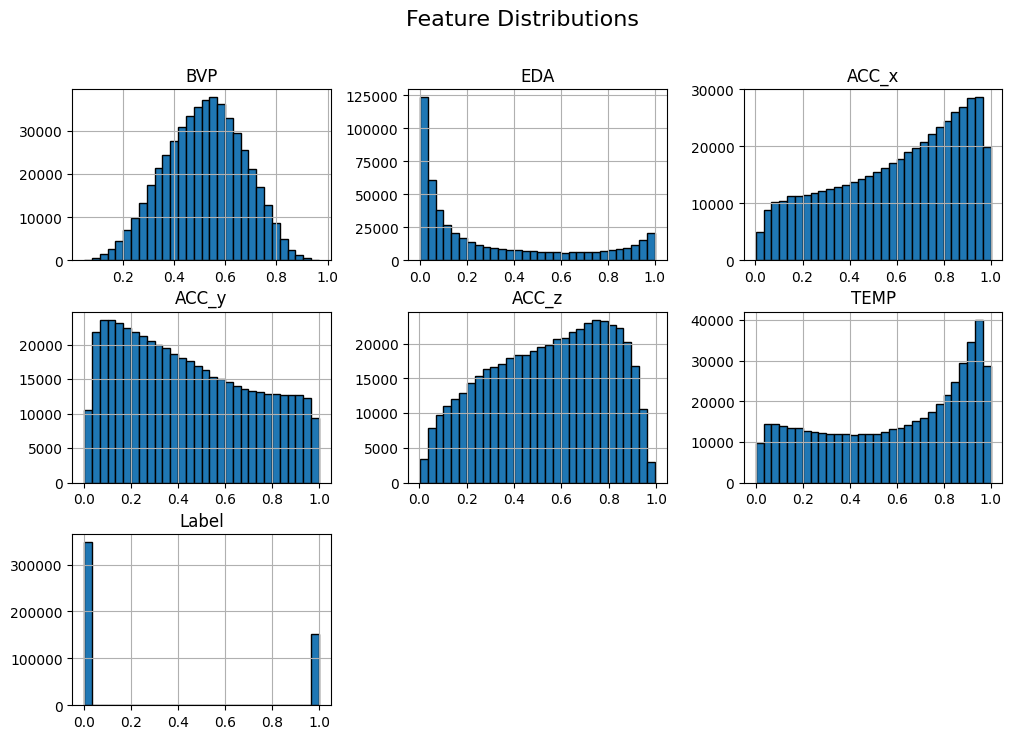

In [52]:
df.hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.suptitle("Feature Distributions", fontsize=16)
plt.show()

#### Check skewness of each feature

In [53]:
skewness = df.skew()
print("\n🔹 Skewness of Features:\n", skewness)


🔹 Skewness of Features:
 BVP     -0.098485
EDA      0.942337
ACC_x   -0.437480
ACC_y    0.303148
ACC_z   -0.235579
TEMP    -0.391911
Label    0.846300
dtype: float64


#### Visualize skewness with boxplots

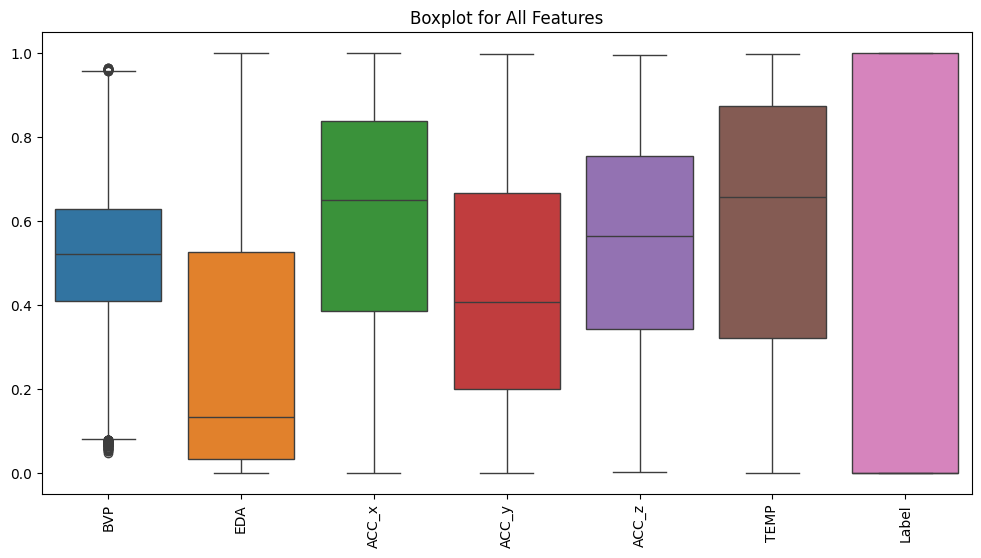

In [54]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df)
plt.xticks(rotation=90)
plt.title("Boxplot for All Features")
plt.show()

# Outliers Handling

#### Other Method for handling outliers
- As in medical dataset outliers can be usefull as for the person with some un-normal health condition, the values give by the sensors can be very much different from a normal person.

- But there is a range in which a value of sensor can come for a person, and values outside this range are unrealistic values like a temperature of person can go upto 103-104 F but not to 150 F.

#### Realistic Ranges for the give sensors (considering both noraml person and patients)
- BVP (Blood Volume Pulse): Normal readings range from -5 to 5, but patients may exhibit up to -10 or 10 in extreme cases.
- EDA (Electrodermal Activity - skin conductance): Normal is 1 to 20 μS, but patients under stress or dehydration may show 0.1 to 40 μS.
- ACC_x, ACC_y, ACC_z (Accelerometer readings - body movement): Normal range is -3g to 3g, but extreme movement or sensor errors might register from -5g to 5g.
- TEMP (Temperature - in Celsius):
  - Normal body temp: 36°C - 37.5°C
  - Mild fever: 37.5°C - 38.9°C
  - High fever: 39°C - 41°C
  - Critical hyperthermia: Above 41°C is rare but possible
  - Hypothermia: Less than 35°C is dangerous
  - Unrealistic cases: Below 30°C or above 43°C

- Use Mean ± 3*Std for normal-like distributions
- Use 1st–99th percentile for skewed data

In [55]:
# Define thresholds dynamically
thresholds = {}

# 1. Use Mean ± 3*Std for normal-like distributions
for col in ["BVP", "ACC_x", "ACC_y", "ACC_z"]:
    mean, std = df[col].mean(), df[col].std()
    thresholds[col] = (mean - 3 * std, mean + 3 * std)

# 2. Use 1st–99th percentile for skewed data (EDA & TEMP)
for col in ["EDA", "TEMP"]:
    thresholds[col] = (df[col].quantile(0.01), df[col].quantile(0.99))

# Print threshold values
print("Thresholds used for outlier detection:")
for col, (low, high) in thresholds.items():
    print(f"{col}: {low:.4f} to {high:.4f}")

# 3. Remove unrealistic values based on the chosen method
for col, (low, high) in thresholds.items():
    df = df[(df[col] >= low) & (df[col] <= high)]

print(f"New dataset size after cleaning: {df.shape}")

Thresholds used for outlier detection:
BVP: 0.0586 to 0.9780
ACC_x: -0.2207 to 1.4229
ACC_y: -0.3887 to 1.2734
ACC_z: -0.2040 to 1.2905
EDA: 0.0017 to 0.9907
TEMP: 0.0219 to 0.9872
New dataset size after cleaning: (480052, 7)


In [56]:
df = df.reset_index(drop=True)

In [57]:
print(df.shape)  # Check the dimensions
print(df.head())  # See if it contains data

(480052, 7)
        BVP       EDA     ACC_x     ACC_y     ACC_z      TEMP  Label
0  0.238061  0.060423  0.679059  0.546219  0.101528  0.832719    0.0
1  0.512416  0.185067  0.862687  0.289050  0.377825  0.971284    0.0
2  0.633430  0.034485  0.311667  0.352741  0.741557  0.905328    0.0
3  0.527648  0.067444  0.384237  0.895484  0.941244  0.132496    0.0
4  0.676393  0.310103  0.408717  0.059676  0.141336  0.888549    0.0


#### Recheck distributions after cleaning


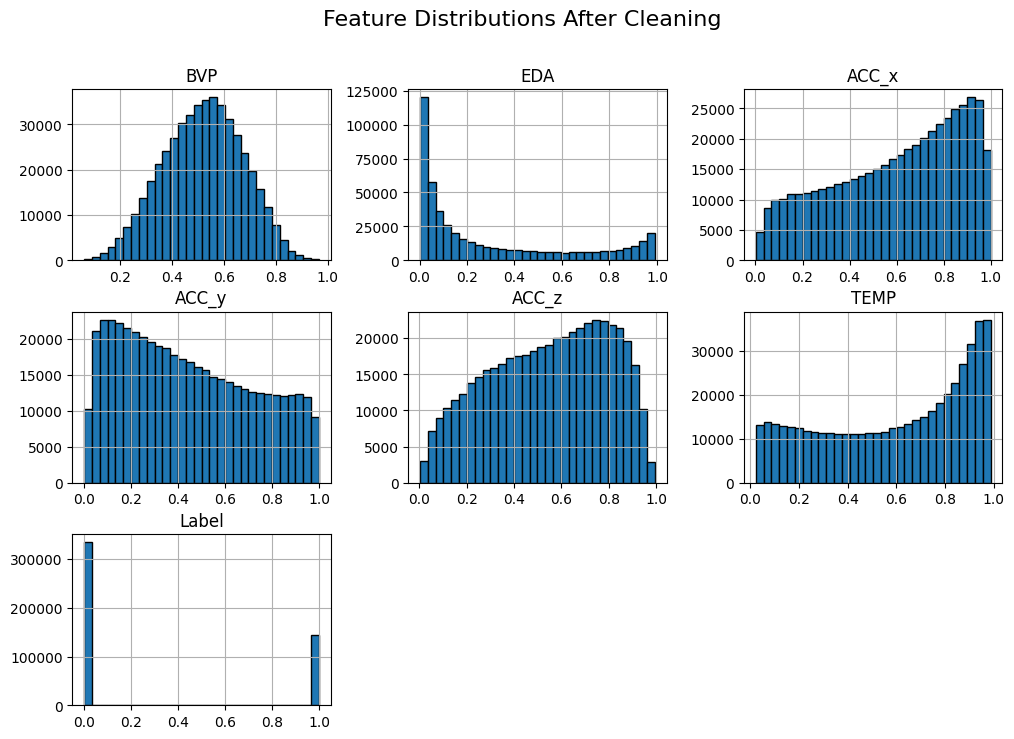

In [58]:
df.hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.suptitle("Feature Distributions After Cleaning", fontsize=16)
plt.show()

#### Handling Skewness

Identify highly skewed features (threshold > 0.5)

In [59]:

skewed_features = skewness[abs(skewness) > 0.5].index
print("\n🔹 Highly Skewed Features:\n", skewed_features)


🔹 Highly Skewed Features:
 Index(['EDA', 'Label'], dtype='object')


 Apply transformations: log1p for right-skewed, sqrt for moderate skew

In [60]:

for col in skewed_features:
  if col=="EDA":
      if df[col].min() > 0:  # Log transformation only for positive values
          df[col] = np.log1p(df[col])
      else:  # Use square root transformation if log is not possible
          df[col] = np.sqrt(df[col] - df[col].min() + 1)
  else:
    pass

#### Visualize new distributions

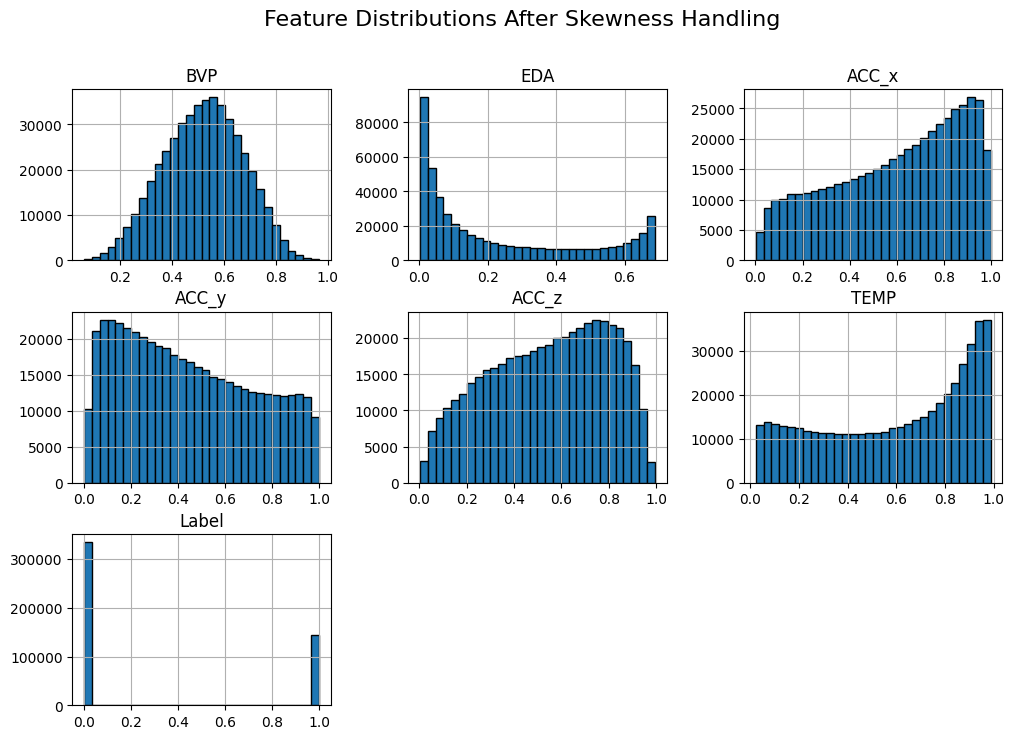

In [61]:
df.hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.suptitle("Feature Distributions After Skewness Handling", fontsize=16)
plt.show()

## Normalizing Dataset
- Using MinMaxScaler

In [62]:
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df.iloc[:, :-1]), columns=df.columns[:-1])
df_scaled["Label"] = df["Label"].values  # Keep labels unchanged

#### Visualize scaled distributions

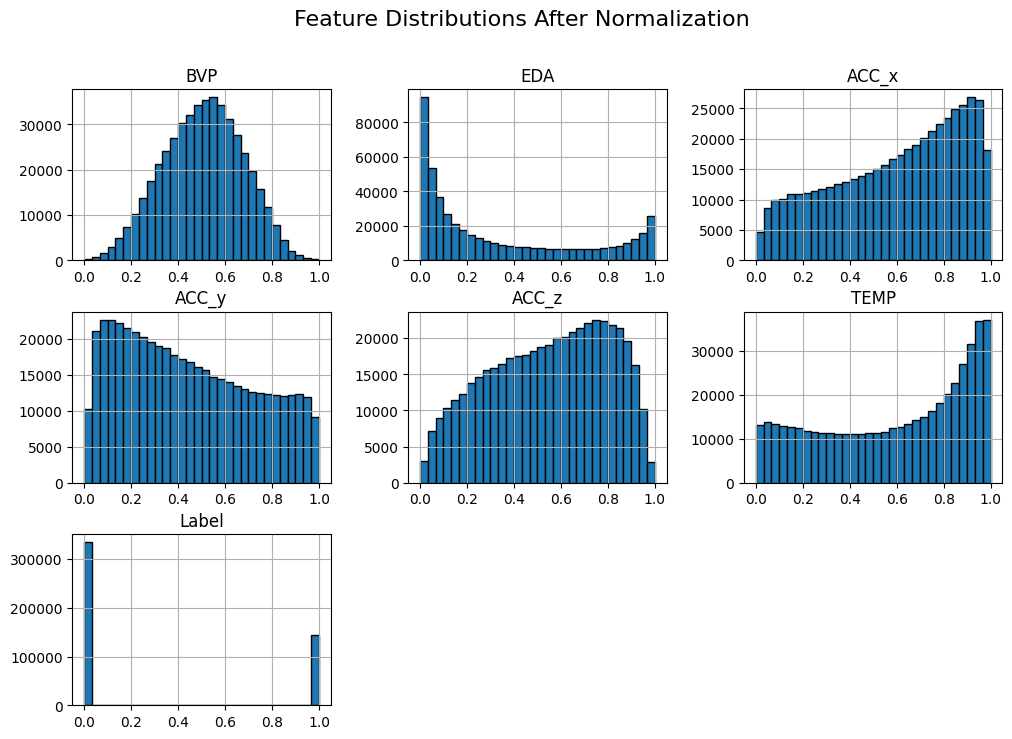

In [63]:
df_scaled.hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.suptitle("Feature Distributions After Normalization", fontsize=16)
plt.show()

- The features in the dataset are already normalized a bit, so the plots are coming the same

In [64]:
label_data.unique()

array([0., 1.])

# Visualization of Dataset
- For the full dataset the collab notebook was crashing
- so I choose a smaller subset of it

#### Correlation Heatmap


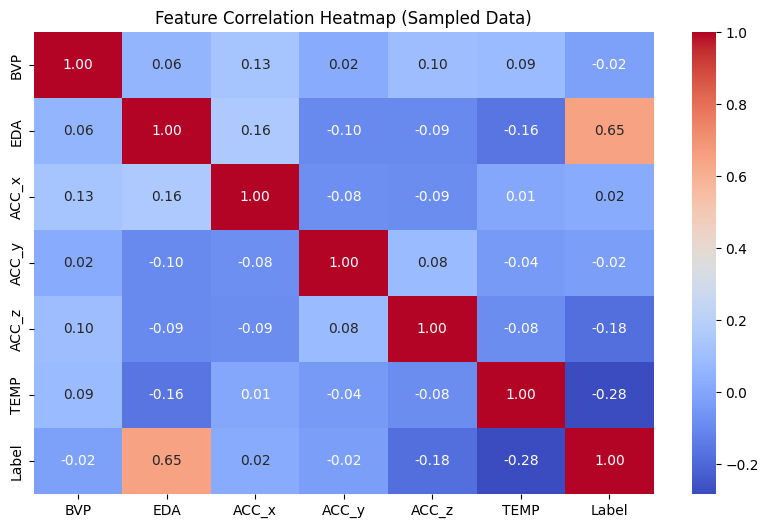

In [65]:
# df_sample = df_scaled.sample(n=500000, random_state=42)  # Take a smaller sample
plt.figure(figsize=(10, 6))
sns.heatmap(df_scaled.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap (Sampled Data)")
plt.show()

- here we can see that EDA is highly related to Labels
- BVP values are very less correlated to labels

In [66]:
from sklearn.model_selection import train_test_split

# Take a stratified sample of 50,000 rows while maintaining label distribution
df_sample, _ = train_test_split(df_scaled, train_size=50000, stratify=df["Label"], random_state=42)

# Verify that the label distribution is similar
print("Original Label Distribution:\n", df["Label"].value_counts(normalize=True))
print("\nSampled Label Distribution:\n", df_sample["Label"].value_counts(normalize=True))

Original Label Distribution:
 Label
0.0    0.697206
1.0    0.302794
Name: proportion, dtype: float64

Sampled Label Distribution:
 Label
0.0    0.6972
1.0    0.3028
Name: proportion, dtype: float64


#### Pairplot to visualize feature relationships

- Detecting patterns and correlations between features
- Identifying separability of classes (classification problems)
- Observing clusters and potential outliers

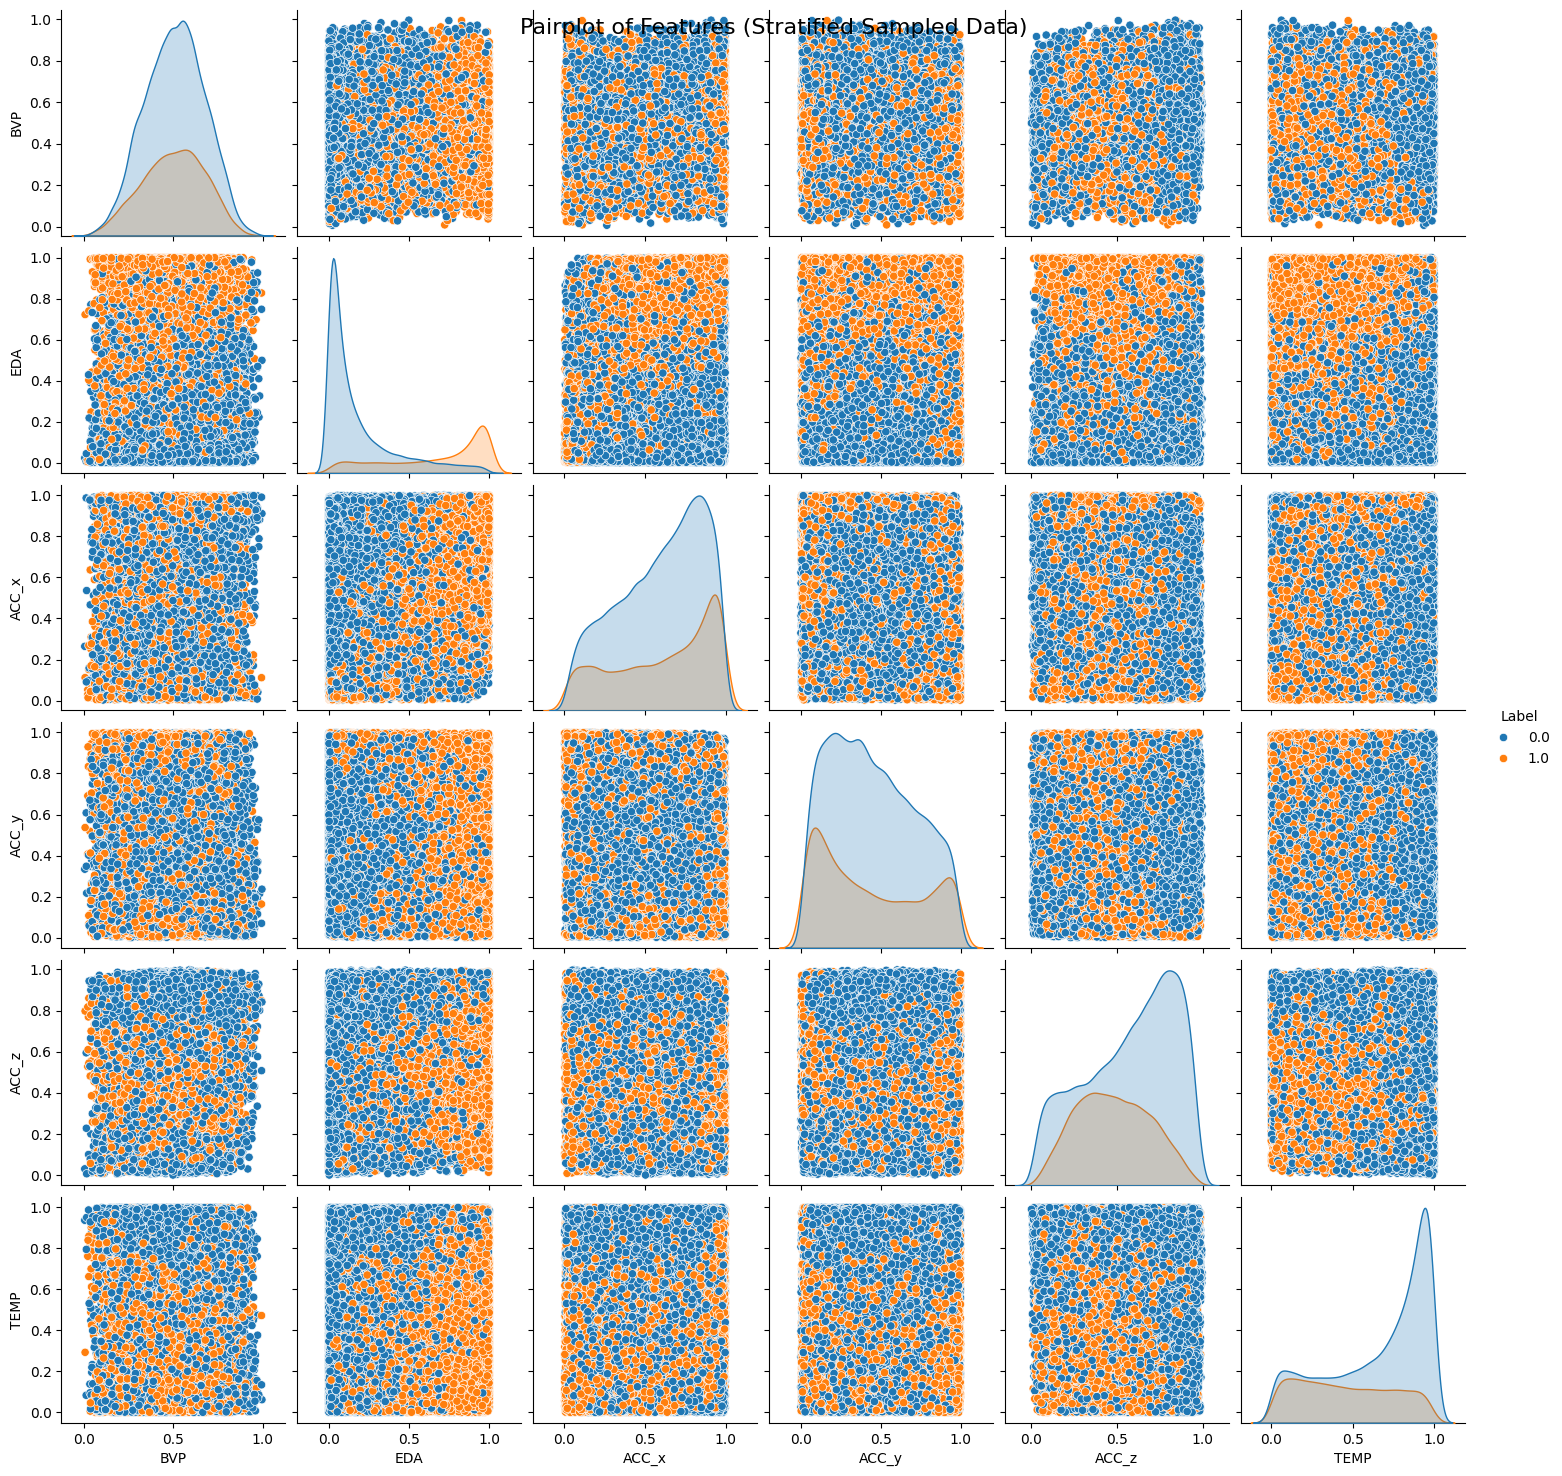

In [67]:
sns.pairplot(df_sample, hue="Label", diag_kind="kde")
plt.suptitle("Pairplot of Features (Stratified Sampled Data)", fontsize=16)
plt.show()

#### Histograms for Data Distribution

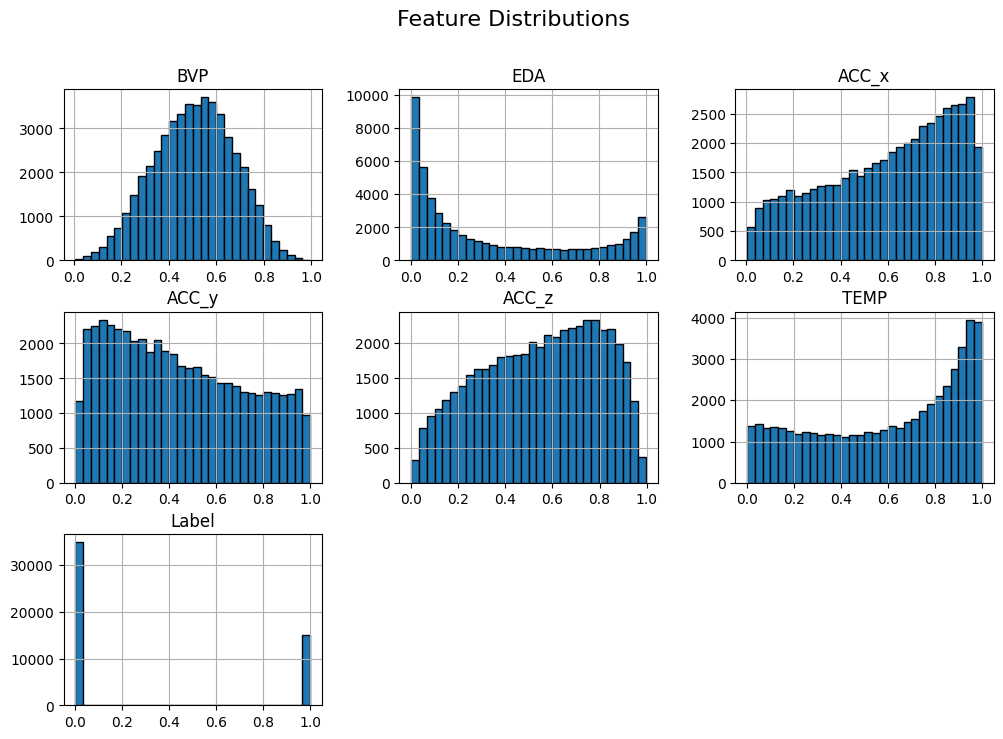

In [68]:
df_sample.hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.suptitle("Feature Distributions", fontsize=16)
plt.show()

#### Violin plots for distribution of key features
- Shows distribution shape
- Highlights density differences for each label
- Helps compare spread and skewness between different labels

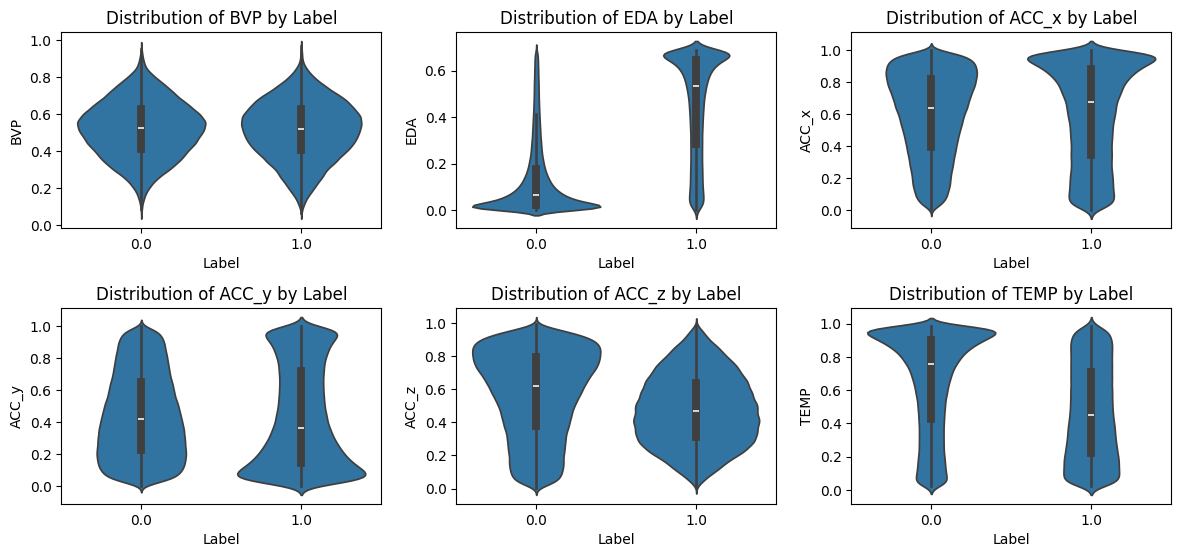

In [69]:
plt.figure(figsize=(12, 8))
for i, col in enumerate(df_sample.columns[:-1]):  # Exclude Label column
    plt.subplot(3, 3, i + 1)
    sns.violinplot(x="Label", y=col, data=df)
    plt.title(f"Distribution of {col} by Label")
plt.tight_layout()
plt.show()

Here we can see that different features wrt labels
- we can see that higher EDA values have higher density at label 1
- BVP values are not so much affecteing by Labels

#### Countplot of Labels

<ipython-input-70-ab6f8d719fa3>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Label", data=df_sample, palette="Set2")


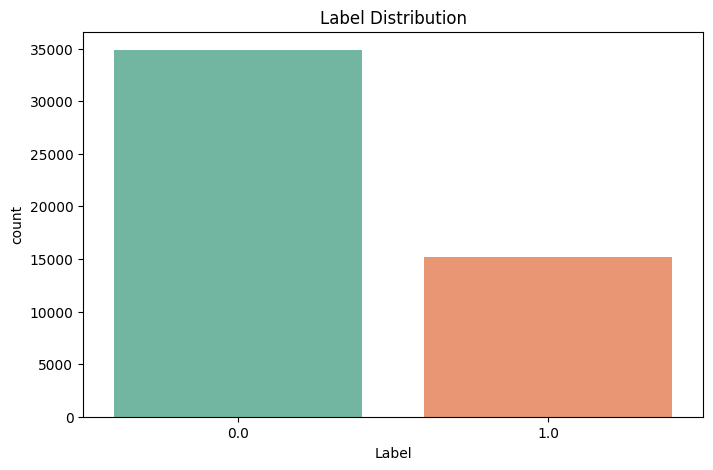

In [70]:
plt.figure(figsize=(8, 5))
sns.countplot(x="Label", data=df_sample, palette="Set2")
plt.title("Label Distribution")
plt.show()

Our dataset have a nearly 7:0 of labels(0, 1)
- we can also see it from here
- Sampled Label Distribution:
  - Label
  - 0.0  ---      0.6972
  - 1.0  ---      0.3028

#### Pairwise Relationships Using Jointplot

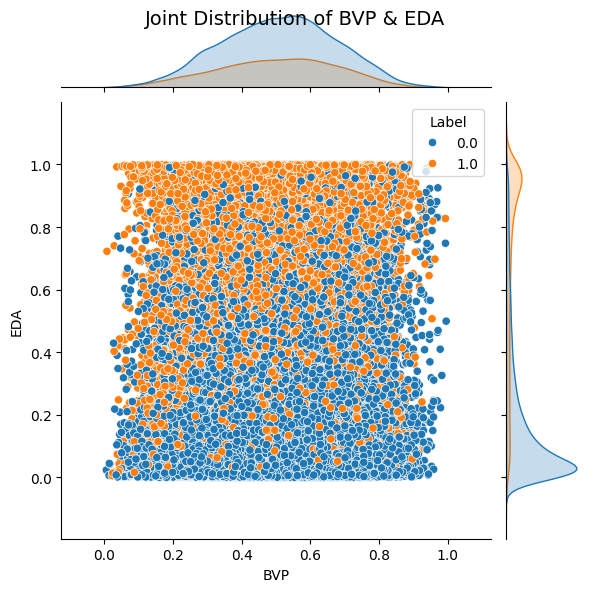

In [71]:
sns.jointplot(x="BVP", y="EDA", data=df_sample, kind="scatter", hue="Label")
plt.suptitle("Joint Distribution of BVP & EDA", fontsize=14)
plt.show()

- Labels are polarized by the values of EDA
- Here both labbels are concentrated at the middle of the range of BVP

- Here we can see that Labels can easily be classified using EDA values
- As both labels are concentrated at the same place for BVP values it is hard to classify labels using BVP values